
PATIENT: P1046
CT: shape=(192, 224, 192), min=-1024.00, max=3000.00, mean=-455.52, std=635.49
MRI: shape=(192, 224, 192), min=0.00, max=1182.00, mean=134.54, std=171.69
Mask: shape=(192, 224, 192), min=0.00, max=1.00, mean=0.57, std=0.49

PATIENT: P2622
CT: shape=(192, 224, 192), min=-1024.00, max=3000.00, mean=-525.22, std=603.72
MRI: shape=(192, 224, 192), min=0.00, max=1196.00, mean=111.60, std=156.06
Mask: shape=(192, 224, 192), min=0.00, max=1.00, mean=0.51, std=0.50

PATIENT: P2658
CT: shape=(192, 224, 192), min=-1024.00, max=3000.00, mean=-485.18, std=645.96
MRI: shape=(192, 224, 192), min=0.00, max=858.00, mean=104.05, std=143.99
Mask: shape=(192, 224, 192), min=0.00, max=1.00, mean=0.53, std=0.50

Comparison: P1046 vs P2622

CT
Exactly identical: False
Mean absolute difference: 224.0499977232918

MR
Exactly identical: False
Mean absolute difference: 78.42052798800998

MASK
Exactly identical: False
Mean absolute difference: 0.08848099481491815

Comparison: P1046 vs P2658

CT
E

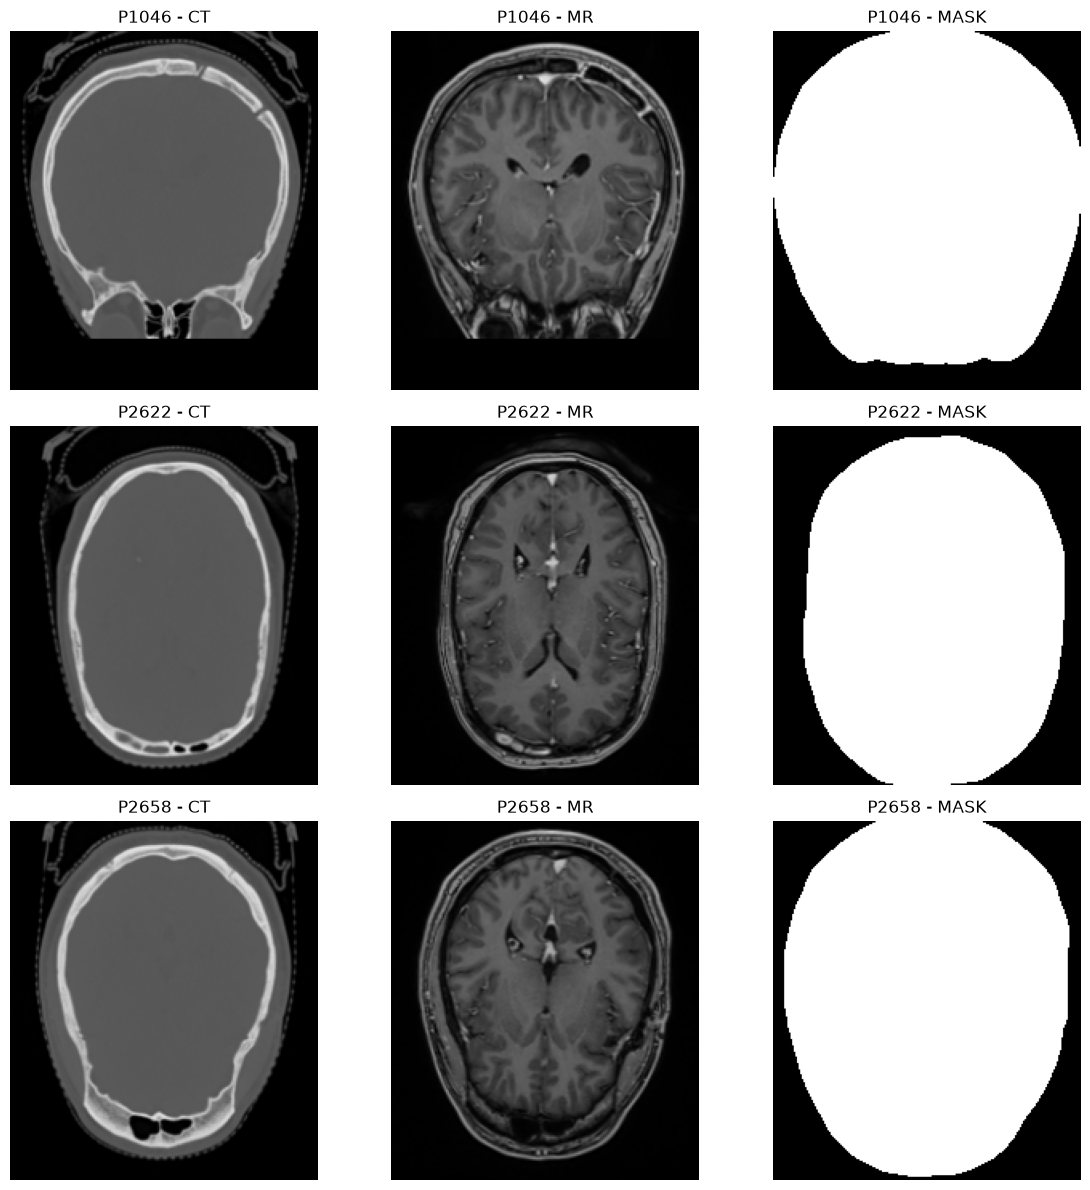

In [1]:

import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

BASE = Path(r"D:\PS07_CT2MRI\dataset\volumes")

# The three patient IDs from your screenshots
patient_ids = ["P1046", "P2622", "P2658"]

volumes = {}

# Load and inspect each patient
for pid in patient_ids:
    folder = BASE / pid

    ct = nib.load(str(folder / "ct.nii.gz")).get_fdata()
    mr = nib.load(str(folder / "mr.nii.gz")).get_fdata()
    mask = nib.load(str(folder / "mask.nii.gz")).get_fdata()

    volumes[pid] = {"ct": ct, "mr": mr, "mask": mask}

    print("\n", "=" * 45)
    print("PATIENT:", pid)

    for name, data in [
        ("CT", ct), ("MRI", mr), ("Mask", mask)
    ]:
        print(
            f"{name}: shape={data.shape}, "
            f"min={data.min():.2f}, "
            f"max={data.max():.2f}, "
            f"mean={data.mean():.2f}, "
            f"std={data.std():.2f}"
        )

# Compare each patient with the first patient
reference = volumes[patient_ids[0]]

for pid in patient_ids[1:]:
    print("\nComparison:", patient_ids[0], "vs", pid)

    for name in ["ct", "mr", "mask"]:
        a = reference[name]
        b = volumes[pid][name]

        print(f"\n{name.upper()}")
        print("Exactly identical:", np.array_equal(a, b))
        print("Mean absolute difference:", np.mean(np.abs(a - b)))

# Visualize all three patients
slice_idx = 96

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, pid in enumerate(patient_ids):
    for col, name in enumerate(["ct", "mr", "mask"]):
        data = volumes[pid][name][:, :, slice_idx].T

        if name == "ct":
            axes[row, col].imshow(
                data, cmap="gray", origin="lower",
                vmin=-1000, vmax=2000
            )
        elif name == "mr":
            axes[row, col].imshow(
                data, cmap="gray", origin="lower",
                vmin=0, vmax=1000
            )
        else:
            axes[row, col].imshow(
                data, cmap="gray", origin="lower",
                vmin=0, vmax=1
            )

        axes[row, col].set_title(f"{pid} - {name.upper()}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.savefig("patient_comparison.png", dpi=150)
plt.show()
